In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error



In [ ]:
df=pd.read_csv("regression_dataset.csv")
df.head(5)

,Study_Hours,Attendance,Previous_Score,Exam_Score
0,2,65,55,48
1,3,70,60,56
2,4,75,65,63
3,5,80,70,71
4,6,85,75,78


In [5]:
df.shape

(15, 4)

In [7]:
df.columns.to_list()


['Study_Hours', 'Attendance', 'Previous_Score', 'Exam_Score']

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Study_Hours     15 non-null     int64
 1   Attendance      15 non-null     int64
 2   Previous_Score  15 non-null     int64
 3   Exam_Score      15 non-null     int64
dtypes: int64(4)
memory usage: 612.0 bytes


In [10]:
df.isnull().sum()

Study_Hours       0
Attendance        0
Previous_Score    0
Exam_Score        0
dtype: int64

In [12]:
pearson_corr = df.corr(method="pearson")
display(pearson_corr.round(3))

,Study_Hours,Attendance,Previous_Score,Exam_Score
Study_Hours,1.000,0.993,0.992,0.994
Attendance,0.993,1.000,0.996,0.999
Previous_Score,0.992,0.996,1.000,0.997
Exam_Score,0.994,0.999,0.997,1.000


In [13]:
spearman_corr = df.corr(method='spearman')
display(spearman_corr.round(3))

,Study_Hours,Attendance,Previous_Score,Exam_Score
Study_Hours,1.000,0.994,0.994,0.994
Attendance,0.994,1.000,1.000,1.000
Previous_Score,0.994,1.000,1.000,1.000
Exam_Score,0.994,1.000,1.000,1.000


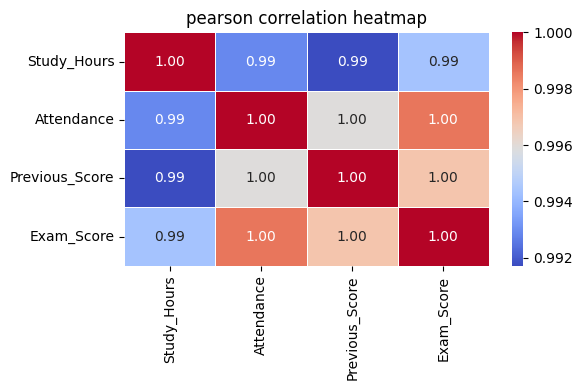

In [15]:
plt.figure(figsize=(6,4))
sns.heatmap(pearson_corr,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5)
plt.title("pearson correlation heatmap")
plt.tight_layout()
plt.show()

In [19]:
X = df[["Study_Hours"]]
y = df["Exam_Score"]
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)
model = LinearRegression()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
print("actual exam score : ", y_test.tolist())
print("predicted exam score : ", y_pred.round(2).tolist())
print("regression Coefficient : ",round(model.coef_[0],2))
print("intercept :", round(model.intercept_,2))

actual exam score :  [81, 74, 48]
predicted exam score :  [78.35, 70.34, 46.3]
regression Coefficient :  8.01
intercept : 30.28


In [21]:
r2 = r2_score(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
print("regression model evolution")
print("-"*35)
print(f"R2_score : {r2:.4f}")
print(f"MAE : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

regression model evolution
-----------------------------------
R2_score : 0.9614
MAE : 2.6721
RMSE : 2.7902


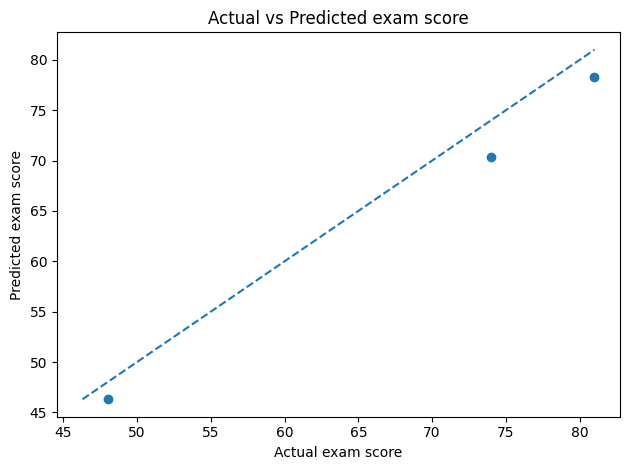

In [24]:
plt.Figure(figsize=(4,6))
plt.scatter(y_test,y_pred)
plt.xlabel("Actual exam score")
plt.ylabel("Predicted exam score")
plt.title("Actual vs Predicted exam score")
min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())
plt.plot([min_score,max_score],[min_score,max_score],linestyle="--")
plt.tight_layout()

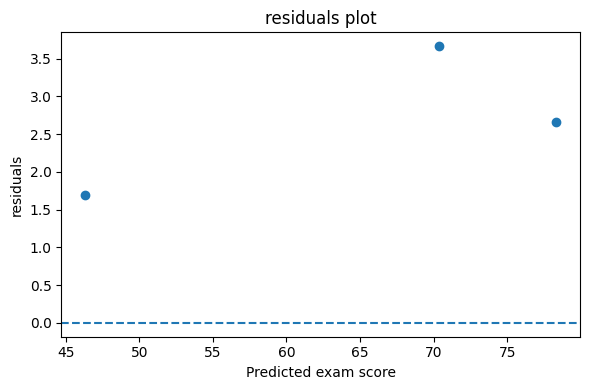

[2.65, 3.66, 1.7]


In [28]:
residuals = y_test - y_pred
plt.figure(figsize=(6,4))
plt.scatter(y_pred,residuals)
plt.axhline(y=0,linestyle="--")
plt.xlabel("Predicted exam score")
plt.ylabel("residuals")
plt.title("residuals plot")
plt.tight_layout()
plt.show()
print(residuals.round(2).tolist())

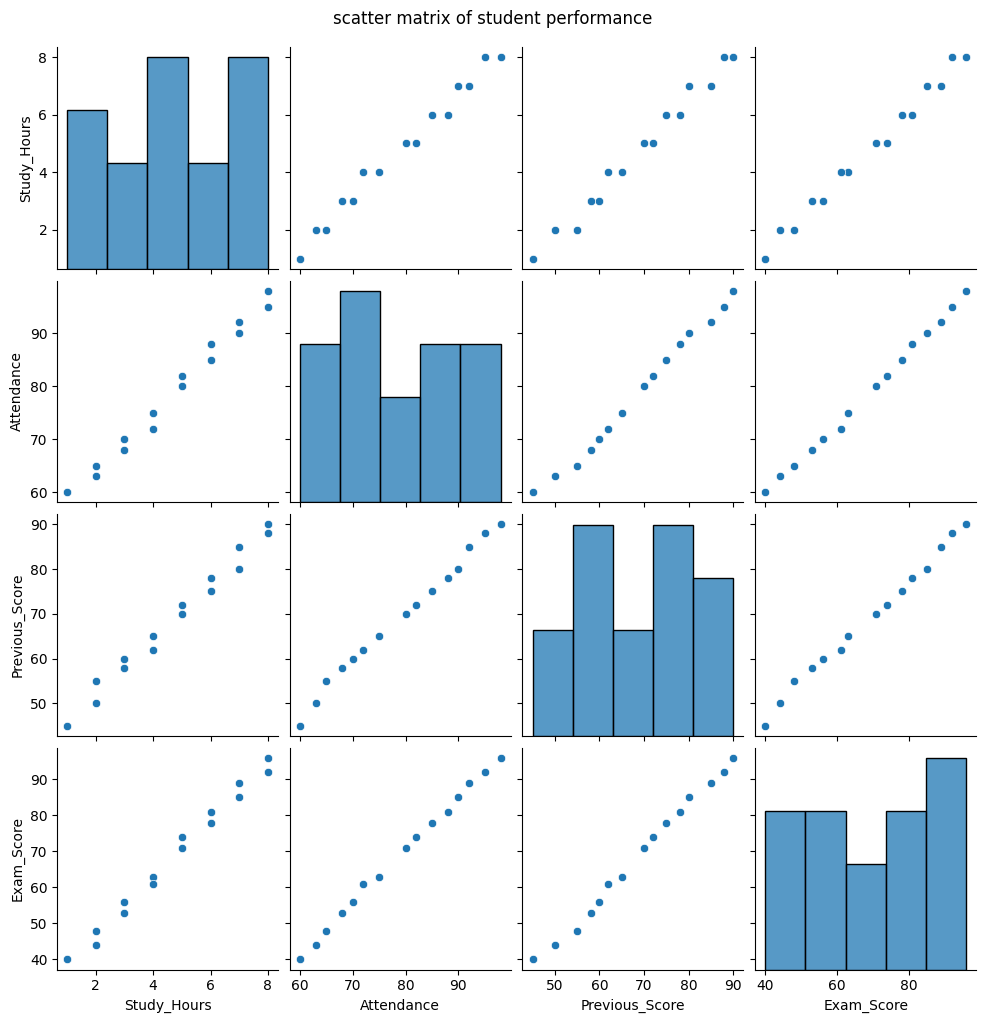

In [30]:
sns.pairplot(df,diag_kind="hist")
plt.suptitle("scatter matrix of student performance",y=1.02)
plt.show()

In [33]:
X_multi = df[ ["Study_Hours", "Attendance", "Previous_Score"]]
y_multi = df["Exam_Score"]
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi,y_multi,test_size=0.2, random_state=42
)
multi_model = LinearRegression()
multi_model.fit(X_train_multi,y_train_multi)
y_pred_multi = multi_model.predict(X_test_multi)
print("multiple linear regression")
print("-"*35)
print("Actual score : ", y_test_multi.tolist())
print("Predict score : ", y_pred_multi.round(2).tolist())
print("\n model coefficents :")
for feature, coefficient in zip(X_multi.columns,multi_model.coef_):
    print(f"{feature}:{coefficient:.4f}")
    print("intercept : ", round(multi_model.intercept_, 4))

multiple linear regression
-----------------------------------
Actual score :  [81, 74, 48]
Predict score :  [81.16, 72.76, 48.75]

 model coefficents :
Study_Hours:1.3051
intercept :  -26.9528
Attendance:0.8081
intercept :  -26.9528
Previous_Score:0.3740
intercept :  -26.9528


In [34]:
r2_multi = r2_score(y_test_multi, y_pred_multi)
mae_multi = mean_absolute_error(y_test_multi, y_pred_multi)
rmse_multi = np.sqrt(mean_squared_error(y_test_multi, y_pred_multi))
print("multiple linear regression - model evalution")
print("-" * 40)
print(f"R2 score : {r2_multi :.4f}")
print(f"MAE : {mae_multi :.4f}")
print(f"RMSE : {rmse_multi : 4f}")

multiple linear regression - model evalution
----------------------------------------
R2 score : 0.9965
MAE : 0.7169
RMSE :  0.840879


In [35]:
comparision = pd.DataFrame({
    "model":["simple linear regression","multiple linear regression"],
    "R2_score":[r2_score(y_test,y_pred),r2_score(y_test_multi,y_pred_multi)],
    "MAE":[mean_absolute_error(y_test,y_pred),mean_absolute_error(y_test_multi,y_pred_multi)],
    "RMSE":[np.sqrt(mean_squared_error(y_test,y_pred)),np.sqrt(mean_squared_error(y_test_multi,y_pred_multi))]})
display(comparision.round(4))

,model,R2_score,MAE,RMSE
0,simple linear regression,0.9614,2.6721,2.7902
1,multiple linear regression,0.9965,0.7169,0.8409


# Week 4 — Day 3: Regression Analysis

## 1. Objective
The objective of this analysis is to study relationships between student performance variables using Pearson and Spearman correlation and build regression models to predict exam scores.

## 2. Dataset Description
The dataset contains 15 sample records and 4 numerical columns:
- Study_Hours
- Attendance
- Previous_Score
- Exam_Score

## 3. Correlation Analysis
Pearson and Spearman correlation coefficients were calculated to understand relationships between the numerical variables. A correlation heatmap and scatter matrix were created to visualise these relationships.

The sample dataset shows strong positive relationships between study hours, attendance, previous scores, and exam scores.

## 4. Regression Models
Two regression models were developed:
- Simple Linear Regression: Uses Study_Hours to predict Exam_Score.
- Multiple Linear Regression: Uses Study_Hours, Attendance, and Previous_Score to predict Exam_Score.

## 5. Model Evaluation
Both models were evaluated using:
- R² Score
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)

The models were compared using these metrics to understand their predictive performance.

## 6. Residual Analysis
A residual plot was created to examine prediction errors. Residuals represent the differences between actual and predicted exam scores.

## 7. Conclusion
This exercise demonstrates how correlation analysis and linear regression can help analyse relationships between variables and predict numerical outcomes.

Note: The dataset contains artificially created sample data for learning purposes. The results should not be treated as conclusions about actual student performance.